In [1]:
import h5py

In [2]:
import sys


In [3]:
import numpy as np
import pandas as pd
import scanpy as sc
import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import joblib
import anndata as ad
from scipy.signal import find_peaks
import h5py



In [4]:
prot = joblib.load("C:\\Users\\olesk\\data\\all_prot_0318.sav")

In [5]:
prot.shape

(239958, 720)

In [6]:
len_prot = int(prot.shape[0]/6)
win_len = int(prot.shape[1]/18)

In [7]:
def short_ab(prot):
    prot_ab = prot[:,int((win_len*0+win_len/2)-2):int((win_len*0+win_len/2)+1)]
    for n in range(1,18):
        tmp_prot  = prot[:,int((win_len*n+win_len/2)-2):int((win_len*n+win_len/2)+1)]
        prot_ab = np.concatenate((prot_ab, tmp_prot), axis=1)
        
    return prot_ab

In [8]:
prot_ab = short_ab(prot)

In [9]:
prot_ab.shape

(239958, 54)

In [10]:
prot_d = joblib.load("C:\\Users\\olesk\\data\\all_prot_cycdi_0318.sav")

In [11]:
umap_d_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_cycdi_0318.sav")

In [ ]:
prot_d = joblib.load("C:\\Users\\olesk\\data\\all_prot_cycdi_1026.sav")
prot_e = joblib.load("C:\\Users\\olesk\\data\\all_prot_cycei_1026.sav")
prot_a = joblib.load("C:\\Users\\olesk\\data\\all_prot_cycai_1026.sav")
prot_b = joblib.load("C:\\Users\\olesk\\data\\all_prot_cycbi_1026.sav")

In [12]:
prot_d_ab = short_ab(prot_d)

In [ ]:
prot_e_ab = short_ab(prot_e)
prot_a_ab = short_ab(prot_a)
prot_b_ab = short_ab(prot_b)

In [13]:
prot_ab = np.concatenate((prot_ab, prot_d_ab), axis=0)

In [ ]:
prot_ab = np.concatenate((prot_ab, prot_e_ab), axis=0)
prot_ab = np.concatenate((prot_ab, prot_a_ab), axis=0)
prot_ab = np.concatenate((prot_ab, prot_b_ab), axis=0)

In [14]:
len_prot = int(prot.shape[0]/6)
win_len = int(prot.shape[1]/18)

In [15]:
prot_ab = np.float32(prot_ab)

In [16]:
umap_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_0318.sav")

In [ ]:
umap_d_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_cycdi_1026.sav")
umap_e_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_cycei_1026.sav")
umap_a_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_cycai_1026.sav")
umap_b_embed = joblib.load("C:\\Users\\olesk\\data\\embedding_cycbi_1026.sav")

In [17]:
umap_embed = np.concatenate((umap_embed, umap_d_embed), axis=0)

In [ ]:
umap_embed = np.concatenate((umap_embed, umap_e_embed), axis=0)
umap_embed = np.concatenate((umap_embed, umap_a_embed), axis=0)
umap_embed = np.concatenate((umap_embed, umap_b_embed), axis=0)

In [18]:
adata = ad.AnnData(prot_ab)

In [19]:
adata.X.dtype

dtype('float32')

In [20]:
adata.obs_names = [f"win_{i:d}" for i in range(adata.n_obs)]

In [21]:
prot_names = ["skp2", "p21", "pp21", "cdh1", "myc", "cycD", "cycD-p21", 
        "Rb", "pRb", "E2F", "E2F-Rb", "cycE", "cycE-p21", "cycA", "cycA-p21",
        "cycB", "cycB-p21", "cdc20"]

all_names = []
for name in prot_names:
    tmp_name = [f"{name}_{i:d}" for i in range(win_len)]
    all_names = all_names + tmp_name

In [22]:
name20 = []
for n in range(18):
    tmp_prot = [all_names[int((win_len*n+win_len/2)-2)], all_names[int((win_len*n+win_len/2)-1)], all_names[int((win_len*n+win_len/2))]]
    name20.extend(tmp_prot)

In [23]:
adata.var_names = name20

In [ ]:
dt = ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot


In [24]:
dt = ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot + ['DMSO']*len_prot + ['ERL']*len_prot


In [25]:
adata.obs["drug"] = pd.Categorical(dt)

In [ ]:
st = [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2 + [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2 + [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2 + [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2 + [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2


In [26]:
st = [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2 + [0.2]*len_prot*2 + [4]*len_prot*2 + [55]*len_prot*2


In [27]:
adata.obs["stiffness"] = pd.Categorical(st)

In [ ]:
inhib = ['none']*len_prot*6 + ['cycDi']*len_prot*6 + ['cycEi']*len_prot*6 + ['cycAi']*len_prot*6 + ['cycBi']*len_prot*6

In [28]:
inhib = ['none']*len_prot*6 + ['cycDi']*len_prot*6

In [29]:
adata.obs["inhibitor"] = pd.Categorical(inhib)

In [30]:
adata.obsm["X_umap"] = umap_embed

In [31]:
def getIMT(prot):
    peaks_E, _ = find_peaks(prot[:,int((win_len*11+win_len/2)-1)], prominence = 40/200, distance = 10)
    peaks_cdc, _ = find_peaks(prot[:,int((win_len*17+win_len/2)-1)], prominence = 40/200, distance = 10)
    
    time_st = 0.1
    
    tmp = np.empty((peaks_E[3],1))
    tmp[:] = np.nan
    tmp_ind = tmp
    div_time = pd.DataFrame(tmp)

    div_inds = pd.DataFrame(tmp)
    ii=0
    
    for n in range(3,len(peaks_E)-3):   #make sure we have divisions at ends 
        tmp_g1_s = peaks_E[n]
        tmp_g1_s_2 = peaks_E[n+1]
        tmp_g1_s_3 = peaks_E[n+2]  
        
        tmp_mit = peaks_cdc[(tmp_g1_s < peaks_cdc) & (peaks_cdc < tmp_g1_s_2)]
        tmp_mit2 = peaks_cdc[(tmp_g1_s_2 < peaks_cdc) & (peaks_cdc < tmp_g1_s_3)]
          
             
        if (np.size(tmp_mit) > 0) & (np.size(tmp_mit2)>0):
            ordered = [tmp_g1_s, tmp_mit[0], tmp_g1_s_2, tmp_mit2[0], tmp_g1_s_3]
            g1_len_tmp = np.array([ordered[2]*time_st]) - np.array([ordered[1]*time_st])
            tmp = [g1_len_tmp]*int(ordered[2]-ordered[0])
            tmp_ind = [np.array([ii])]*int(ordered[2]-ordered[0])
            tmp = np.concatenate(tmp, axis=0)
            tmp_ind = np.concatenate(tmp_ind, axis=0)
            tmp_df = pd.DataFrame(tmp)
            tmp_df_ind = pd.DataFrame(tmp_ind)

            div_time = pd.concat([div_time, tmp_df], ignore_index=True)
            div_inds = pd.concat([div_inds, tmp_df_ind], ignore_index=True)
            ii+=1
        else:
            tmp = np.empty((int(peaks_E[n+1]-peaks_E[n]),1))
            tmp[:] = np.nan
            tmp_df = pd.DataFrame(tmp)
            div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
            div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
            ii+=1
    
    tmp = np.empty((len(prot)-peaks_E[-3],1))
    tmp[:] = np.nan
    tmp_df = pd.DataFrame(tmp)
    div_time = pd.concat([div_time, tmp_df], ignore_index=True) 
    div_inds = pd.concat([div_inds, tmp_df], ignore_index=True)
    
    return div_time, div_inds

In [32]:
all_divs = []
all_div_inds = []
for num in range(6):
    tmp_div, div_inds = getIMT(prot[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    tmp_ind_list = div_inds[0].values.tolist()
    all_divs = all_divs + tmp_list
    all_div_inds = all_div_inds + tmp_ind_list
    print(num)

0
1
2
3
4
5


In [33]:
for num in range(6):
    tmp_div, div_inds = getIMT(prot_d[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    tmp_ind_list = div_inds[0].values.tolist()
    all_divs = all_divs + tmp_list
    all_div_inds = all_div_inds + tmp_ind_list
    print(num)

0
1
2
3
4
5


In [ ]:
for num in range(6):
    tmp_div = getIMT(prot_e[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    all_divs = all_divs + tmp_list
    print(num)

In [ ]:
for num in range(6):
    tmp_div = getIMT(prot_a[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    all_divs = all_divs + tmp_list
    print(num)

In [ ]:
for num in range(6):
    tmp_div = getIMT(prot_b[num*len_prot:(num+1)*len_prot,:])
    tmp_list = tmp_div[0].values.tolist()
    all_divs = all_divs + tmp_list
    print(num)

In [34]:
G1_cats = []
for val in all_divs:
    if val <= 15:
        tmp = 'Short'
    elif (val > 15) & (val <= 25):
        tmp = 'Int'
    elif val > 25:
        tmp = 'Long'
    else:
        tmp = 'nan'
    
    G1_cats.append(tmp)

In [35]:
adata.obs["G1_time"] = pd.Categorical(G1_cats)

In [202]:
adata.write('orig_params_0318_w_cycdi.h5ad')

In [ ]:
name20 = []
for n in range(18):
    tmp_prot = [all_names[int((win_len*n+win_len/2)-2)], all_names[int((win_len*n+win_len/2)-1)], all_names[int((win_len*n+win_len/2))]]
    name20.extend(tmp_prot)

In [ ]:
adata20.write('orig_params_ab.h5ad')

In [36]:
adata.obs.columns

Index(['drug', 'stiffness', 'inhibitor', 'G1_time'], dtype='object')

In [37]:
alldata = adata.obs
alldata['G1_val'] = all_divs
alldata['cell_ind'] = all_div_inds
alldata['UMAP1'] = adata.obsm["X_umap"][:,0]
alldata['UMAP2'] = adata.obsm["X_umap"][:,1]
# alldata['G1_time'] = adata.obs["G1_time"]
n=1
for name in prot_names:
    alldata[f"{name}"] = adata.X[:,n]
    n+=3

In [38]:
test = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0.2) & (alldata['inhibitor'] == 'none')]


In [39]:
tmp = test.loc[(test['G1_time'] == 'Long')]

In [40]:
tmp

,drug,stiffness,inhibitor,G1_time,G1_val,cell_ind,UMAP1,UMAP2,skp2,p21,...,pRb,E2F,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20
win_40633,ERL,0.2,none,Long,30.1,1.0,-0.618082,5.933055,0.08,0.001685,...,0.810559,0.447115,0.071429,0.482412,0.068627,0.475676,0.050505,0.191710,0.169492,0.040
win_40634,ERL,0.2,none,Long,30.1,1.0,-0.829664,5.877622,0.10,0.003371,...,0.813665,0.418269,0.102679,0.417085,0.068627,0.497297,0.070707,0.222798,0.169492,0.035
win_40635,ERL,0.2,none,Long,30.1,1.0,-0.892407,5.971297,0.10,0.001124,...,0.826087,0.423077,0.066964,0.427136,0.068627,0.562162,0.040404,0.248705,0.152542,0.080
win_40636,ERL,0.2,none,Long,30.1,1.0,-1.064375,6.005285,0.14,0.002247,...,0.832298,0.418269,0.075893,0.396985,0.068627,0.589189,0.070707,0.284974,0.152542,0.090
win_40637,ERL,0.2,none,Long,30.1,1.0,-1.100225,6.115240,0.18,0.003371,...,0.795031,0.346154,0.125000,0.301508,0.029412,0.605405,0.060606,0.279793,0.152542,0.120
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
win_78908,ERL,0.2,none,Long,30.4,219.0,7.269368,7.305252,0.02,0.045506,...,0.621118,0.283654,0.191964,0.095477,0.588235,0.091892,0.535354,0.119171,0.457627,0.025
win_78909,ERL,0.2,none,Long,30.4,219.0,6.916197,7.281099,0.00,0.011798,...,0.745342,0.418269,0.084821,0.206030,0.441176,0.135135,0.505050,0.129534,0.457627,0.045
win_78910,ERL,0.2,none,Long,30.4,219.0,6.735711,7.249730,0.00,0.007865,...,0.751553,0.461538,0.053571,0.316583,0.284314,0.227027,0.424242,0.145078,0.406780,0.085
win_78911,ERL,0.2,none,Long,30.4,219.0,6.623317,7.222081,0.02,0.005056,...,0.763975,0.471154,0.044643,0.341709,0.254902,0.324324,0.373737,0.150259,0.389830,0.060


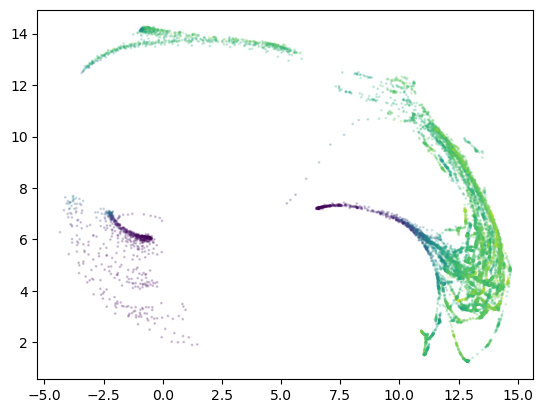

In [41]:
plt.scatter(tmp.UMAP1, tmp.UMAP2, c=tmp.Rb, s=1, alpha=0.2)

In [292]:
test = alldata.loc[(alldata['drug'] == 'ERL') & (alldata['stiffness'] == 0.2) & (alldata['inhibitor'] == 'none')]


In [293]:
test

,drug,stiffness,inhibitor,G1_time,UMAP1,UMAP2,skp2,p21,pp21,cdh1,...,E2F-Rb,cycE,cycE-p21,cycA,cycA-p21,cycB,cycB-p21,cdc20,G1_val,cell_ind
win_39993,ERL,0.2,none,nan,-0.886833,1.452255,0.26,0.000000,0.009142,0.025,...,0.156250,0.678392,0.000000,0.659459,0.030303,0.150259,0.016949,0.060,NaN,NaN
win_39994,ERL,0.2,none,nan,-1.281370,1.572942,0.28,0.000000,0.006966,0.030,...,0.120536,0.643216,0.000000,0.686486,0.020202,0.165803,0.016949,0.095,NaN,NaN
win_39995,ERL,0.2,none,nan,-1.750278,1.814167,0.30,0.000000,0.006095,0.010,...,0.107143,0.592965,0.009804,0.681081,0.040404,0.202073,0.000000,0.105,NaN,NaN
win_39996,ERL,0.2,none,nan,-2.212224,2.181541,0.32,0.000562,0.003918,0.015,...,0.147321,0.507538,0.019608,0.697297,0.040404,0.191710,0.000000,0.090,NaN,NaN
win_39997,ERL,0.2,none,nan,-2.730999,2.619081,0.24,0.000562,0.004789,0.035,...,0.138393,0.427136,0.019608,0.686486,0.070707,0.212435,0.000000,0.065,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
win_79981,ERL,0.2,none,nan,13.191021,5.362427,0.06,0.659551,0.056596,0.985,...,0.312500,0.005025,0.245098,0.000000,0.454545,0.056995,0.389830,0.025,NaN,NaN
win_79982,ERL,0.2,none,nan,13.156400,5.268790,0.06,0.666854,0.055725,0.930,...,0.312500,0.000000,0.254902,0.010811,0.434343,0.056995,0.389830,0.030,NaN,NaN
win_79983,ERL,0.2,none,nan,13.123871,5.236765,0.04,0.658427,0.054419,0.935,...,0.330357,0.010050,0.235294,0.016216,0.424242,0.056995,0.389830,0.050,NaN,NaN
win_79984,ERL,0.2,none,nan,13.125364,5.246582,0.08,0.647191,0.053983,0.955,...,0.325893,0.005025,0.245098,0.010811,0.434343,0.031088,0.474576,0.020,NaN,NaN


In [42]:
tmp_ls = test.loc[(test['G1_time'] == 'Short') | (test['G1_time'] == 'Long')]

In [43]:
tmp_s = tmp_ls.loc[(tmp_ls['G1_time'] == 'Short')]
tmp_l = tmp_ls.loc[(tmp_ls['G1_time'] == 'Long')]

In [79]:
def plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool):
    xmin, xmax = -10, 20
    ymin, ymax = 0, 20
    
    if short_bool:        
        x = np.array(tmp_s.UMAP1)
        y = np.array(tmp_s.UMAP2)
        H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='gray', s=0.5, alpha=0.2)
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)

    else:
        x = np.array(tmp_l.UMAP1)
        y = np.array(tmp_l.UMAP2)
        H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
        x_centers = xedges[:-1] + np.diff(xedges)/2
        y_centers = yedges[:-1] + np.diff(yedges)/2
        
        ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='gray', s=0.5, alpha=0.2)
        ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l[prot], s=0.5, alpha=0.2, vmin=0, vmax=1)
        
    ax.set_xlim(xmin,xmax)
    ax.set_ylim(ymin,ymax)
    ax.xaxis.set_ticks(np.arange(-10, 21, step=10))
    ax.yaxis.set_ticks(np.arange(0, 21, step=5))
    ax.tick_params(colors='white', which='both') 
    ax.set_title(prot, y=1.0, pad=-14, size=12)
    # plt.xticks(color='w')
    # plt.yticks(color='w')
    

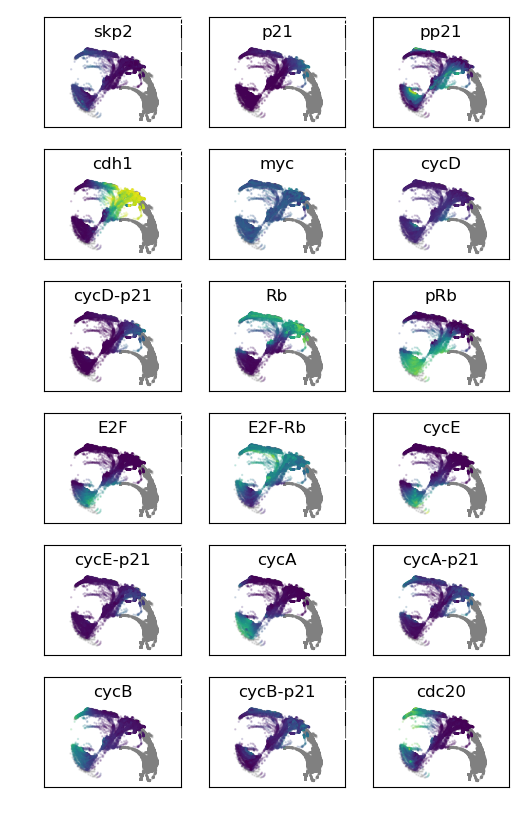

In [80]:
size = (6,10)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=True)
    n+=1

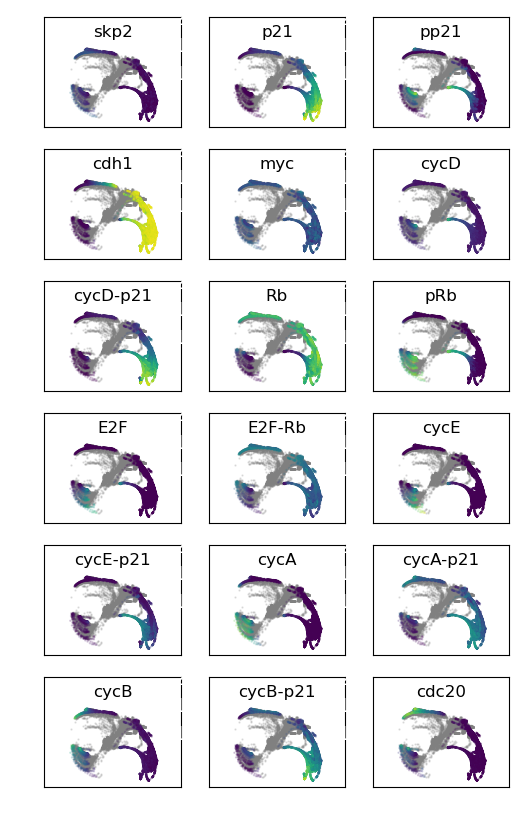

In [81]:
size = (6,10)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)
nrows = 6
ncols = 3

fig = plt.figure(figsize=size)

n=1
for prot in prot_names:
    ax = fig.add_subplot(nrows, ncols, n)
    plot_act(ax, fig, prot, tmp_s, tmp_l, short_bool=False)
    n+=1

(array([ 0,  5, 10, 15, 20]),
 [Text(0, 0, '0'),
  Text(0, 5, '5'),
  Text(0, 10, '10'),
  Text(0, 15, '15'),
  Text(0, 20, '20')])

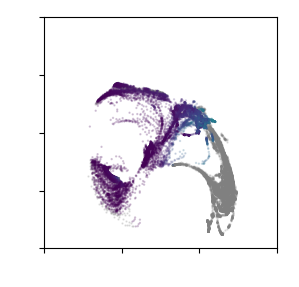

In [55]:
size = (3,3)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig, ax = plt.subplots(1,1, figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(tmp_s.UMAP1)
y = np.array(tmp_s.UMAP2)
H_s, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

ax.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='gray', s=0.5, alpha=0.2)
ax.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c=tmp_s['cycD-p21'], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

(array([ 0,  5, 10, 15, 20]),
 [Text(0, 0, '0'),
  Text(0, 5, '5'),
  Text(0, 10, '10'),
  Text(0, 15, '15'),
  Text(0, 20, '20')])

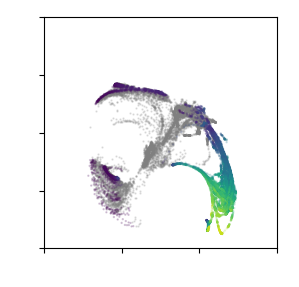

In [442]:
size = (3,3)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

x = np.array(tmp_l.UMAP1)
y = np.array(tmp_l.UMAP2)
H_l, xedges, yedges = np.histogram2d(y, x, bins=100, range= [[ymin,ymax], [xmin,xmax]], density=True)
x_centers = xedges[:-1] + np.diff(xedges)/2
y_centers = yedges[:-1] + np.diff(yedges)/2

plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='gray', s=0.5, alpha=0.2)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c=tmp_l['cycD-p21'], s=0.5, alpha=0.2, vmin=0, vmax=1)

plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))
plt.xticks(color='w')
plt.yticks(color='w')

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=size)

In [298]:
import matplotlib.path as mpltPath

In [52]:
H_s = np.swapaxes(H_s,0,1)
H_l = np.swapaxes(H_l,0,1)

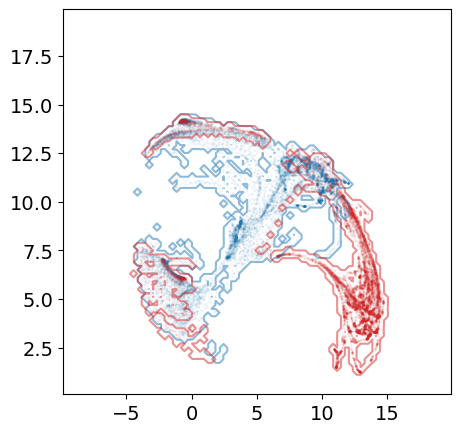

In [299]:
# max_level = 0.01
# min_level = 0.001
# step_level = 0.01
val = 0.0001
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

# c1 = plt.contour(y_centers, x_centers, H, levels = np.arange(min_level, max_level + step_level, step_level))
c1 = plt.contour(y_centers, x_centers, H_s, [val], colors='tab:blue', alpha=0.5)
c2 = plt.contour(y_centers, x_centers, H_l, [val], colors='tab:red', alpha=0.5)

plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='tab:blue', s=0.2, alpha=0.1)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='tab:red', s=0.2, alpha=0.1)

In [300]:
def OnePointInsideContour(contourArray, PointTuple, tol):
    L = len(contourArray);
    y0 = PointTuple[0]; # horizontal
    x0 = PointTuple[1]; # vertical
    ret = [];
    inside = False;
    counter = 0

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if ycont > y0 - tol and ycont < y0 + tol and xcont > x0: 
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if ycont > y0 - tol and ycont < y0 + tol and xcont < x0: 
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break           

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if xcont > x0 - tol and xcont < x0 + tol and ycont < y0:
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break  

    for k in range(L):
        ycont = list(contourArray[k])[0];
        xcont = list(contourArray[k])[1];
        if xcont > x0 - tol and xcont < x0 + tol and ycont > y0: 
            p = (ycont, xcont); 
            counter += 1; 
            ret.append(p);
            break

    if counter == 4:
        inside = True

    return inside, ret

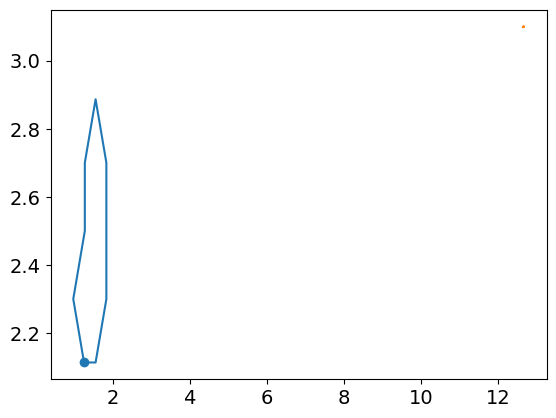

In [301]:
plt.plot(c1.allsegs[0][1][:,0], c1.allsegs[0][1][:,1])
plt.plot(c2.allsegs[0][3][:,0], c2.allsegs[0][3][:,1])
plt.scatter(c1.allsegs[0][1][0,0], c1.allsegs[0][1][0,1])

In [302]:
tmp_p = [(c1.allsegs[0][1][0,0], c1.allsegs[0][1][0,1])]
tmp_p

[(1.25, 2.113584)]

In [219]:
cont = c1.allsegs[0][1]

In [201]:
tmp_p = [(5, 10)]

In [258]:
len(c2.allsegs[0])

54

In [220]:
path = mpltPath.Path(cont)


In [223]:
inside2 = path.contains_points(tmp_p)
inside2

array([False])

In [193]:
test, ret = OnePointInsideContour(c1.allsegs[0][1], tmp_p, 0.2)
test

False

In [312]:
all_segs = c2.allsegs[0]

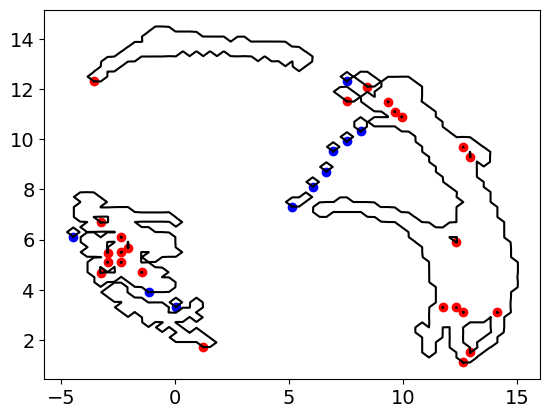

In [382]:
fig = plt.figure()

all_bools = []

for seg in range(35):
    tmp_p = [(all_segs[seg][0,0], all_segs[seg][0,1])]
    
    tmp_bools = []
    for seg2 in range(len(all_segs)):
        path = mpltPath.Path(all_segs[seg2])
        tmp_bool = path.contains_points(tmp_p)
#             tmp_bool, ret = OnePointInsideContour(c1.allsegs[0][seg2], tmp_p, 0.2)
#             tmp_bools.append(tmp_bool)
        tmp_bools.append(tmp_bool)
    if any(tmp_bools):
        all_bools.append(True)
        plt.scatter(all_segs[seg][0,0], all_segs[seg][0,1], c='red')
    else:
        all_bools.append(False)
        plt.scatter(all_segs[seg][0,0], all_segs[seg][0,1], c='blue')
    plt.plot(all_segs[seg][:,0], all_segs[seg][:,1], c='black')

In [305]:
any(tmp_bools)

False

In [306]:
def checkContainContour(all_segs):
# all_segs = c1.allsegs[0]
    all_bools = []

    for seg in range(len(all_segs)):
        tmp_p = [(all_segs[seg][0,0], all_segs[seg][0,1])]

        tmp_bools = []
        for seg2 in range(len(all_segs)):
            path = mpltPath.Path(all_segs[seg2])
            tmp_bool = path.contains_points(tmp_p)
            tmp_bools.append(tmp_bool)
        if any(tmp_bools):
            all_bools.append(True)
        else:
            all_bools.append(False)

    return all_bools

In [338]:
c1bools = checkContainContour(c1.allsegs[0])
# c1bools[2] = False
c1_unique = [x for i, x in enumerate(c1.allsegs[0]) if not c1bools[i]]

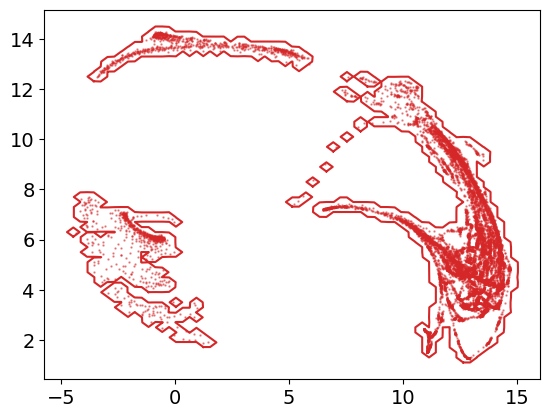

In [387]:
c2bools = checkContainContour(c2.allsegs[0])
c2bools[0] = False
c2bools[2] = False
c2bools[31] = False
c2bools[32] = False
c2bools[33] = False
c2_unique = [x for i, x in enumerate(c2.allsegs[0]) if not c2bools[i]]


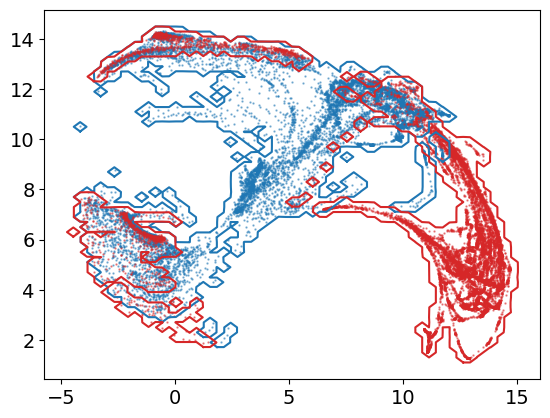

In [388]:
for seg in range(len(c1_unique)):
    plt.plot(c1_unique[seg][:,0], c1_unique[seg][:,1], c='tab:blue')
    
for seg in range(len(c2_unique)):
# for seg in range(3):
    plt.plot(c2_unique[seg][:,0], c2_unique[seg][:,1], c='tab:red')
    
plt.scatter(tmp_s.UMAP1, tmp_s.UMAP2, c='tab:blue', s=0.5, alpha=0.5)
plt.scatter(tmp_l.UMAP1, tmp_l.UMAP2, c='tab:red', s=0.5, alpha=0.5)

In [389]:
s_points =[(tmp_s.UMAP1.iloc[n], tmp_s.UMAP2.iloc[n]) for n in range(len(tmp_s))]
l_points =[(tmp_l.UMAP1.iloc[n], tmp_l.UMAP2.iloc[n]) for n in range(len(tmp_l))]

In [390]:
short_in_long_bool = [False] *len(s_points)

In [391]:
for n in range(len(c2_unique)):
    path = mpltPath.Path(c2_unique[n])
    tmp_bool = path.contains_points(s_points)
    short_in_long_bool = [a or b for a, b in zip(short_in_long_bool, tmp_bool)]
    

In [392]:
short_in_long = [x for i, x in enumerate(s_points) if short_in_long_bool[i]]
short_not_in = [x for i, x in enumerate(s_points) if not short_in_long_bool[i]]
short_in_long_arr = np.array(short_in_long)
short_not_in = np.array(short_not_in)

In [393]:
long_in_short_bool = [False] *len(l_points)

In [394]:
for n in range(len(c1_unique)):
    path = mpltPath.Path(c1_unique[n])
    tmp_bool = path.contains_points(l_points)
    long_in_short_bool = [a or b for a, b in zip(long_in_short_bool, tmp_bool)]

In [395]:
long_in_short = [x for i, x in enumerate(l_points) if long_in_short_bool[i]]
long_not_in = [x for i, x in enumerate(l_points) if not long_in_short_bool[i]]
long_in_short_arr = np.array(long_in_short)
long_not_in = np.array(long_not_in)

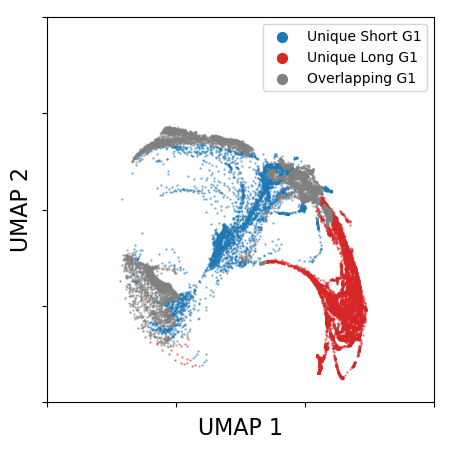

In [413]:
size = (5,5)
params = {'axes.titley': 1,
         'axes.titlepad': 5,
         'axes.labelsize': 16,
         'axes.edgecolor': "black",
         'axes.titlesize': 18,
         'xtick.labelsize': 14,
         'ytick.labelsize': 14}
plt.rcParams.update(params)

fig = plt.figure(figsize=size)
xmin, xmax = -10, 20
ymin, ymax = 0, 20

# for seg in range(len(c1_unique)):
#     plt.plot(c1_unique[seg][:,0], c1_unique[seg][:,1], c='tab:blue')
# for seg in range(len(c2_unique)):
#     plt.plot(c2_unique[seg][:,0], c2_unique[seg][:,1], c='tab:red')

plt.scatter(short_not_in[:,0], short_not_in[:,1], c='tab:blue', s=0.5, alpha=0.5, label="Unique Short G1")
plt.scatter(short_in_long_arr[:,0], short_in_long_arr[:,1], c='grey', s=0.5, alpha=0.5)    
    
plt.scatter(long_not_in[:,0], long_not_in[:,1], c='tab:red', s=0.5, alpha=0.5, label="Unique Long G1")
plt.scatter(long_in_short_arr[:,0], long_in_short_arr[:,1], c='grey', s=0.5, alpha=0.5, label="Overlapping G1")


plt.xlim(xmin,xmax)
plt.ylim(ymin,ymax)
plt.xticks(np.arange(-10, 21, step=10))
plt.yticks(np.arange(0, 21, step=5))

plt.xticks(color='w')
plt.yticks(color='w')

plt.xlabel('UMAP 1', labelpad=-10)
plt.ylabel('UMAP 2', labelpad=-15)

leg = plt.legend(markerscale=10)
for lh in leg.legend_handles: 
    lh.set_alpha(1)
    
    

In [443]:
item_counts = tmp_s["cell_ind"].value_counts()
len(item_counts)

117